# DocSentry: Explainable & Uncertainty-Aware PDF Malware Detection
## Notebook 01: Exploratory Data Analysis & Data Understanding

### Project Context & Objective
**DocSentry** is an explainable, uncertainty-aware machine learning framework for detecting malicious Portable Document Format (PDF) files. 
This notebook performs comprehensive, **read-only** exploratory data analysis on the **EMBER2024 PDF subset**, a modern benchmark dataset collected from VirusTotal between September 2023 and December 2024.

### Notebook Goals
1. **Data Ingestion & Integrity**: Load raw train and test JSONL weekly files; inspect structural dimensions, data types, and memory footprints.
2. **Class Distribution**: Analyze label balance (Benign vs. Malicious) across temporal splits.
3. **Data Quality Audit**: Quantify duplicate records and missing values across all features and metadata.
4. **Feature Family Taxonomy**: Catalog all 32 top-level schema attributes and map active PDF feature families (General File Info, Byte Histogram, Byte-Entropy Histogram, String Statistics).
5. **Metadata & Leakage Segregation**: Formally identify non-input columns (hashes, dates, AV detection ratios, family tags) to prevent data leakage and shortcut learning.
6. **Numerical Profiling**: Inspect sample records and compute descriptive statistical profiles (`describe()`) on key numeric indicators.
7. **Artifact Export**: Generate and save publication-ready exploratory figures to `reports/figures`.

> **Note**: In adherence to strict analytical practices, this notebook is strictly **read-only**; no data modifications, cleaning transformations, or filtering are persisted.


### 0. Environment Setup & Configuration
We configure the runtime environment, import foundational analytical libraries, and define standardized plotting aesthetics.


In [1]:
import os
import glob
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 300

# Directory routing: support execution from repository root or notebooks/ directory
project_root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
raw_dir = project_root / "data" / "raw"
reports_dir = project_root / "reports" / "figures"
reports_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root:  {project_root.resolve()}")
print(f"Raw data dir:  {raw_dir.resolve()}")
print(f"Reports dir:   {reports_dir.resolve()}")


Project root:  <PROJECT_ROOT>
Raw data dir:  <PROJECT_ROOT>\data\raw
Reports dir:   <PROJECT_ROOT>\reports\figures


---
## 1. Load Train and Test Data; Print Shapes, Dtypes, and Memory Usage

The EMBER2024 PDF subset is partitioned temporally into weekly JSON Lines (`.jsonl`) files:
- **Training Set**: 52 weeks spanning September 24, 2023 through September 21, 2024.
- **Test Set**: 12 weeks spanning September 22, 2024 through December 14, 2024.

This temporal split mimics operational reality, testing whether models trained on historical malware can generalize to newer, evolving threats. We load all weekly shards into consolidated DataFrames and inspect their memory footprints.


In [2]:
train_files = sorted(glob.glob(str(raw_dir / "*_train.jsonl")))
test_files = sorted(glob.glob(str(raw_dir / "*_test.jsonl")))

print(f"Discovered {len(train_files)} training files (52 weeks expected).")
print(f"Discovered {len(test_files)} testing files (12 weeks expected).")

# High-performance multi-file reading via Polars converted to Pandas DataFrames
df_train = pl.read_ndjson(train_files).to_pandas()
df_test = pl.read_ndjson(test_files).to_pandas()

train_mem_mb = df_train.memory_usage(deep=True).sum() / (1024 ** 2)
test_mem_mb = df_test.memory_usage(deep=True).sum() / (1024 ** 2)

print("\n" + "=" * 60)
print(f"TRAIN SET: Shape = {df_train.shape} | Memory Usage = {train_mem_mb:.2f} MB")
print(f"TEST SET:  Shape = {df_test.shape}  | Memory Usage = {test_mem_mb:.2f} MB")
print("=" * 60)

# Display column names and data types
dtypes_summary = pd.DataFrame({
    'Train Dtype': df_train.dtypes,
    'Test Dtype': df_test.dtypes,
    'Sample Non-Null (Train)': df_train.notnull().sum(),
    'Sample Non-Null (Test)': df_test.notnull().sum()
})
print("\nDataset Schema (First 15 Columns):")
display(dtypes_summary.head(15))


Discovered 52 training files (52 weeks expected).
Discovered 12 testing files (12 weeks expected).



TRAIN SET: Shape = (104000, 32) | Memory Usage = 272.99 MB
TEST SET:  Shape = (24000, 32)  | Memory Usage = 62.99 MB

Dataset Schema (First 15 Columns):


,Train Dtype,Test Dtype,Sample Non-Null (Train),Sample Non-Null (Test)
md5,str,str,104000,24000
sha1,str,str,104000,24000
sha256,str,str,104000,24000
tlsh,str,str,104000,24000
first_submission_date,int64,int64,104000,24000
last_analysis_date,int64,int64,104000,24000
detection_ratio,str,str,104000,24000
label,int64,int64,104000,24000
file_type,str,str,104000,24000
family,str,str,11422,2702


---
## 2. Label Distribution (Benign vs. Malicious) in Train and Test

Class balance is a fundamental characteristic in security machine learning. 
- `label = 0`: Benign PDF document
- `label = 1`: Malicious PDF document

Here we compute exact counts, relative proportions, and visualize the class distribution across both splits to assess whether class imbalance mitigation strategies will be required.


Class Distribution Summary:

,Class Name,Train Count,Train %,Test Count,Test %
Label,,,,,
0,Benign (0),52000,50.0,12000,50.0
1,Malicious (1),52000,50.0,12000,50.0


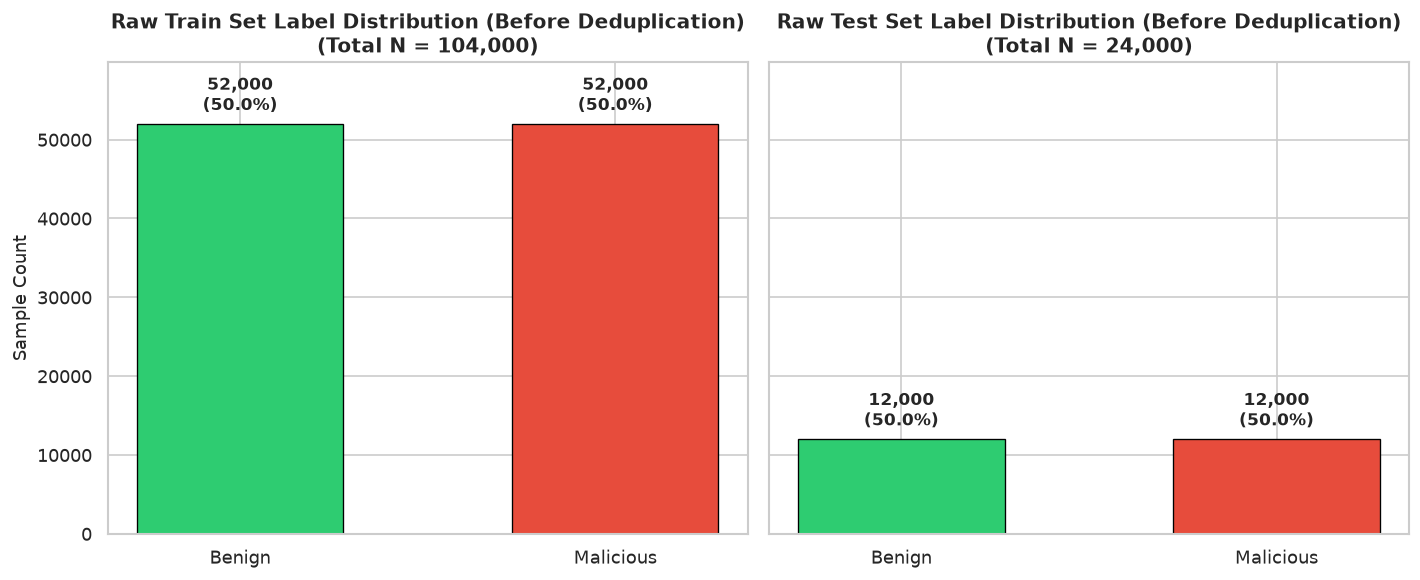

Saved figure to: <PROJECT_ROOT>\reports\figures\01_label_distribution.png


In [3]:
train_counts = df_train['label'].value_counts().sort_index()
test_counts = df_test['label'].value_counts().sort_index()

balance_df = pd.DataFrame({
    'Train Count': train_counts,
    'Train %': (train_counts / len(df_train) * 100).round(2),
    'Test Count': test_counts,
    'Test %': (test_counts / len(df_test) * 100).round(2),
}, index=[0, 1])
balance_df.index.name = 'Label'
balance_df['Class Name'] = ['Benign (0)', 'Malicious (1)']
balance_df = balance_df[['Class Name', 'Train Count', 'Train %', 'Test Count', 'Test %']]

print("Class Distribution Summary:")
display(balance_df)

# Visualization: Side-by-side bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

palette = {'Benign': '#2ecc71', 'Malicious': '#e74c3c'}
class_labels = ['Benign', 'Malicious']

# Train plot
bars_train = axes[0].bar(class_labels, train_counts.values, color=['#2ecc71', '#e74c3c'], width=0.55, edgecolor='black', linewidth=0.8)
axes[0].set_title(f"Raw Train Set Label Distribution (Before Deduplication)\n(Total N = {len(df_train):,})", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Sample Count", fontsize=11)
axes[0].set_ylim(0, max(train_counts.values) * 1.15)
for bar in bars_train:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + (max(train_counts.values)*0.02),
                 f"{yval:,}\n({yval/len(df_train)*100:.1f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Test plot
bars_test = axes[1].bar(class_labels, test_counts.values, color=['#2ecc71', '#e74c3c'], width=0.55, edgecolor='black', linewidth=0.8)
axes[1].set_title(f"Raw Test Set Label Distribution (Before Deduplication)\n(Total N = {len(df_test):,})", fontsize=12, fontweight='bold')
axes[1].set_ylim(0, max(train_counts.values) * 1.15)
for bar in bars_test:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + (max(train_counts.values)*0.02),
                 f"{yval:,}\n({yval/len(df_test)*100:.1f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
fig_path = reports_dir / "01_label_distribution.png"
plt.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_path}")


---
## 3. Count of Duplicate Rows and Missing Values

Data hygiene requires verifying:
1. **Exact Row Duplication**: Whether rows are duplicated in the raw files.
2. **Hash-Level Duplication**: SHA-256 uniqueness within splits and potential leakage across splits (Train-Test overlap).
3. **Missing Value Audit**: Null / NaN / None presence across metadata and extracted feature columns.


In [4]:
# 1. Duplicate hash inspection
train_total = len(df_train)
test_total = len(df_test)

train_unique_sha = df_train['sha256'].nunique()
test_unique_sha = df_test['sha256'].nunique()

train_sha_dups = train_total - train_unique_sha
test_sha_dups = test_total - test_unique_sha

train_test_overlap = set(df_train['sha256']).intersection(set(df_test['sha256']))

print("=== DUPLICATE & INTEGRITY ANALYSIS ===")
print(f"Train Total Rows:        {train_total:,}")
print(f"Train Unique SHA256:     {train_unique_sha:,}")
print(f"Train Duplicate SHA256:  {train_sha_dups:,} ({train_sha_dups/train_total*100:.1f}%)")
print("-" * 50)
print(f"Test Total Rows:         {test_total:,}")
print(f"Test Unique SHA256:      {test_unique_sha:,}")
print(f"Test Duplicate SHA256:   {test_sha_dups:,} ({test_sha_dups/test_total*100:.1f}%)")
print("-" * 50)
print(f"Train-Test SHA256 Overlap (Leakage): {len(train_test_overlap)} samples")

# Check if rows are identical duplicates
sample_sha = df_train[df_train.duplicated('sha256')]['sha256'].iloc[0]
sample_dups = df_train[df_train['sha256'] == sample_sha]
print(f"\nVerification on duplicate SHA256 '{sample_sha[:16]}...':")
print(f"Count of occurrences in train: {len(sample_dups)}")
print(f"Are metadata fields identical? {sample_dups['first_submission_date'].nunique() == 1 and sample_dups['detection_ratio'].nunique() == 1}")


=== DUPLICATE & INTEGRITY ANALYSIS ===
Train Total Rows:        104,000
Train Unique SHA256:     52,000
Train Duplicate SHA256:  52,000 (50.0%)
--------------------------------------------------
Test Total Rows:         24,000
Test Unique SHA256:      12,000
Test Duplicate SHA256:   12,000 (50.0%)
--------------------------------------------------
Train-Test SHA256 Overlap (Leakage): 0 samples

Verification on duplicate SHA256 '00055c9e1f09d82b...':
Count of occurrences in train: 2
Are metadata fields identical? True


,Column,Train Nulls,Train Null %,Test Nulls,Test Null %
10,family_confidence,92578,89.02,21298,88.74
9,family,92578,89.02,21298,88.74


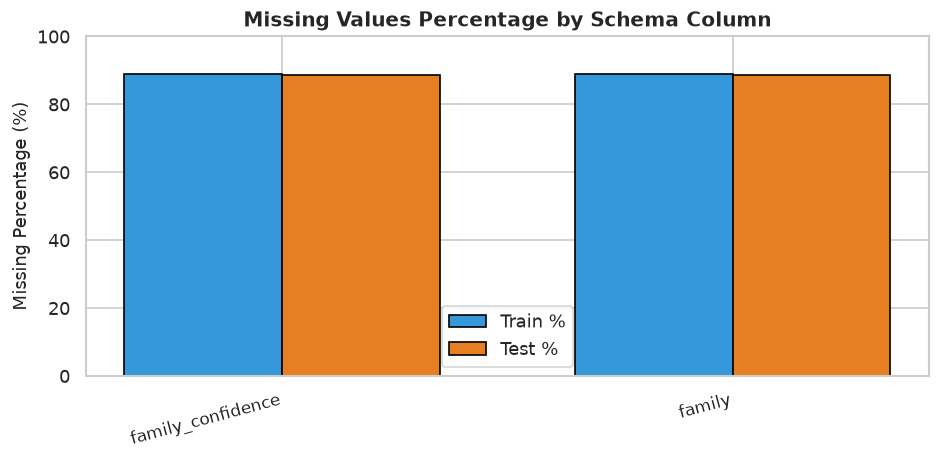

Saved figure to: <PROJECT_ROOT>\reports\figures\02_missing_values.png


In [5]:
# 2. Missing Value Analysis
missing_train = df_train.isnull().sum()
missing_test = df_test.isnull().sum()

missing_df = pd.DataFrame({
    'Column': df_train.columns,
    'Train Nulls': missing_train.values,
    'Train Null %': (missing_train.values / train_total * 100).round(2),
    'Test Nulls': missing_test.values,
    'Test Null %': (missing_test.values / test_total * 100).round(2)
})
missing_df = missing_df.sort_values(by='Train Nulls', ascending=False)
display(missing_df[missing_df['Train Nulls'] > 0])

# Bar chart of missing values
cols_with_nulls = missing_df[missing_df['Train Nulls'] > 0]
if len(cols_with_nulls) > 0:
    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(cols_with_nulls))
    width = 0.35
    ax.bar(x - width/2, cols_with_nulls['Train Null %'], width, label='Train %', color='#3498db', edgecolor='black')
    ax.bar(x + width/2, cols_with_nulls['Test Null %'], width, label='Test %', color='#e67e22', edgecolor='black')
    ax.set_xticks(x)
    ax.set_xticklabels(cols_with_nulls['Column'], rotation=15, ha='right', fontsize=10)
    ax.set_ylabel("Missing Percentage (%)", fontsize=11)
    ax.set_title("Missing Values Percentage by Schema Column", fontsize=12, fontweight='bold')
    ax.set_ylim(0, 100)
    ax.legend()
    plt.tight_layout()
    fig_path = reports_dir / "02_missing_values.png"
    plt.savefig(fig_path, bbox_inches='tight')
    plt.show()
    print(f"Saved figure to: {fig_path}")
else:
    print("No missing values identified in any column.")


---
## 4. List Columns & Group by Feature Family

EMBER feature version 3 (`thrember`) organizes binary representations into modular feature extractors:
For PDF files (non-PE binaries), the PE-specific structural parsers (COFF headers, sections, imports/exports, authenticode) yield empty structures. The malware detection representation for PDFs relies on **4 active feature families** totaling **696 vectorized numerical features**:

1. **General File Info (`general`)**: File size, whole-file Shannon entropy, PE format indicator flag, and first 4 header bytes (7 features).
2. **Byte Histogram (`histogram`)**: Normalized frequency counts of all 256 individual byte values (0x00 to 0xFF) across the file (256 features).
3. **Byte-Entropy Histogram (`byteentropy`)**: 2D joint distribution ($16 \times 16$ grid) approximating the co-occurrence of byte value and local entropy in sliding windows (256 features).
4. **String Statistics (`strings`)**: Printable string counts, average string length, printable character distribution (96 bins), string entropy, and 76 targeted regex match counts including PDF markers (`/URI`, `/FlateDecode`, `/EmbeddedFile`, JavaScript, PowerShell, network IOCs) (177 features).


Sample nested structures:
- 'general' keys (4): ['size', 'entropy', 'is_pe', 'start_bytes']
- 'strings' keys (6): ['numstrings', 'avlength', 'printabledist', 'printables', 'entropy', 'string_counts']
- 'strings.string_counts' regex count: 40
- Sample regex patterns: ['/FlateDecode', '/URI', 'btc_wallet', 'create', 'decode', 'file', 'http://', 'https://']

FEATURE FAMILY TAXONOMY & DIMENSIONALITY


,Feature Family,Raw Column,Active in PDF,Vectorized Dim,Components
0,General File Info,general,Yes,7,"size (1), entropy (1), is_pe (1), start_bytes[..."
1,Byte Histogram,histogram,Yes,256,Byte frequency distribution for all 256 values...
2,Byte-Entropy Histogram,byteentropy,Yes,256,16x16 joint distribution of byte values vs loc...
3,String Statistics & IOCs,strings,Yes,177,"numstrings (1), avlength (1), printables (1), ..."
4,PE Headers & Sections,"header, section",No (PE only),0,"COFF, DOS header, section characteristics, vir..."
5,PE Imports & Exports,"imports, exports",No (PE only),0,Imported and exported DLLs and symbols
6,PE Data Directories & Rich Header,"datadirectories, richheader",No (PE only),0,PE data directories and MSVC Rich Header values
7,Authenticode & Warnings,"authenticode, pefilewarnings",No (PE only),0,"Digital signatures, certificate chains, pefile..."


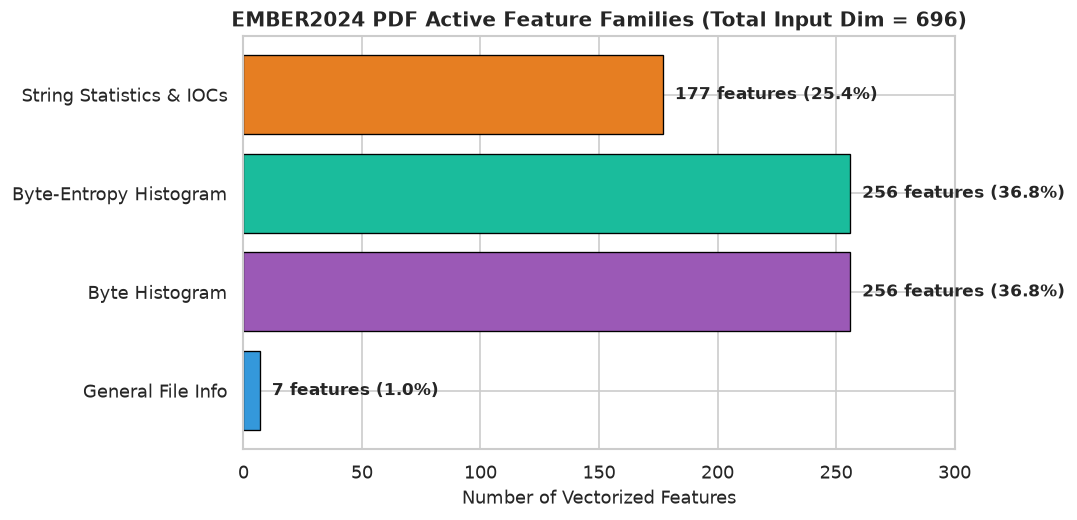

Saved figure to: <PROJECT_ROOT>\reports\figures\03_feature_families.png


In [6]:
# Inspect internal keys within nested dictionary features
sample_row = df_train.iloc[0]

general_keys = list(sample_row['general'].keys()) if isinstance(sample_row['general'], dict) else []
string_keys = list(sample_row['strings'].keys()) if isinstance(sample_row['strings'], dict) else []
regex_keys = list(sample_row['strings'].get('string_counts', {}).keys()) if isinstance(sample_row['strings'], dict) else []

print("Sample nested structures:")
print(f"- 'general' keys ({len(general_keys)}): {general_keys}")
print(f"- 'strings' keys ({len(string_keys)}): {string_keys}")
print(f"- 'strings.string_counts' regex count: {len(regex_keys)}")
print(f"- Sample regex patterns: {regex_keys[:8]}")

# Define feature taxonomy table
families_data = [
    {
        "Feature Family": "General File Info",
        "Raw Column": "general",
        "Active in PDF": "Yes",
        "Vectorized Dim": 7,
        "Components": "size (1), entropy (1), is_pe (1), start_bytes[0..3] (4)",
        "Security Rationale": "Detects anomalous file lengths, packing/compression via entropy, and magic header bytes."
    },
    {
        "Feature Family": "Byte Histogram",
        "Raw Column": "histogram",
        "Active in PDF": "Yes",
        "Vectorized Dim": 256,
        "Components": "Byte frequency distribution for all 256 values (0x00 - 0xFF)",
        "Security Rationale": "Captures raw byte composition; compressed streams, plain text, and shellcode have distinct signatures."
    },
    {
        "Feature Family": "Byte-Entropy Histogram",
        "Raw Column": "byteentropy",
        "Active in PDF": "Yes",
        "Vectorized Dim": 256,
        "Components": "16x16 joint distribution of byte values vs local Shannon entropy",
        "Security Rationale": "Differentiates encrypted payloads, obfuscated streams, and compressed PDF object streams."
    },
    {
        "Feature Family": "String Statistics & IOCs",
        "Raw Column": "strings",
        "Active in PDF": "Yes",
        "Vectorized Dim": 177,
        "Components": "numstrings (1), avlength (1), printables (1), printabledist (96), entropy (1), regexes (76)",
        "Security Rationale": "Identifies suspicious PDF keywords (/URI, /FlateDecode, /EmbeddedFile), JavaScript, URLs, and IPs."
    },
    {
        "Feature Family": "PE Headers & Sections",
        "Raw Column": "header, section",
        "Active in PDF": "No (PE only)",
        "Vectorized Dim": 0,
        "Components": "COFF, DOS header, section characteristics, virtual sizes",
        "Security Rationale": "Not applicable to PDF format (values are empty dicts)."
    },
    {
        "Feature Family": "PE Imports & Exports",
        "Raw Column": "imports, exports",
        "Active in PDF": "No (PE only)",
        "Vectorized Dim": 0,
        "Components": "Imported and exported DLLs and symbols",
        "Security Rationale": "Not applicable to PDF format (values are empty)."
    },
    {
        "Feature Family": "PE Data Directories & Rich Header",
        "Raw Column": "datadirectories, richheader",
        "Active in PDF": "No (PE only)",
        "Vectorized Dim": 0,
        "Components": "PE data directories and MSVC Rich Header values",
        "Security Rationale": "Not applicable to PDF format (values are empty)."
    },
    {
        "Feature Family": "Authenticode & Warnings",
        "Raw Column": "authenticode, pefilewarnings",
        "Active in PDF": "No (PE only)",
        "Vectorized Dim": 0,
        "Components": "Digital signatures, certificate chains, pefile parsing warnings",
        "Security Rationale": "Not applicable to PDF format (values are empty)."
    }
]

df_families = pd.DataFrame(families_data)
print("\n" + "=" * 90)
print("FEATURE FAMILY TAXONOMY & DIMENSIONALITY")
print("=" * 90)
display(df_families[['Feature Family', 'Raw Column', 'Active in PDF', 'Vectorized Dim', 'Components']])

# Bar chart of active feature dimensions
active_families = df_families[df_families['Active in PDF'] == 'Yes']

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(active_families['Feature Family'], active_families['Vectorized Dim'], color=['#3498db', '#9b59b6', '#1abc9c', '#e67e22'], edgecolor='black', linewidth=0.8)
ax.set_xlabel("Number of Vectorized Features", fontsize=11)
ax.set_title(f"EMBER2024 PDF Active Feature Families (Total Input Dim = {active_families['Vectorized Dim'].sum()})", fontsize=12, fontweight='bold')
ax.set_xlim(0, 300)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 5, bar.get_y() + bar.get_height()/2.0, f"{int(w)} features ({w/active_families['Vectorized Dim'].sum()*100:.1f}%)",
            va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
fig_path = reports_dir / "03_feature_families.png"
plt.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_path}")


---
## 5. Identify Metadata Columns (Must NOT Be Used as Model Inputs)

Machine learning models for malware detection are highly susceptible to **shortcut learning** and **data leakage**. Including external indicators (such as hash keys, vendor detection scores, or submission timestamps) allows the classifier to memorize non-generalizable metadata rather than learning intrinsic file structure.

Below is the formal classification of all schema columns into **Prohibited Metadata** vs. **Model Input Features**.


In [7]:
metadata_rules = [
    # Hashes & Identifiers
    {"Column": "md5", "Category": "File Hash / Identifier", "Model Input": "PROHIBITED", "Reason": "Unique content hash; cause high-cardinality memorization with zero generalization."},
    {"Column": "sha1", "Category": "File Hash / Identifier", "Model Input": "PROHIBITED", "Reason": "Unique content hash; leads to lookup-table behavior."},
    {"Column": "sha256", "Category": "File Hash / Identifier", "Model Input": "PROHIBITED", "Reason": "Primary key / sample identifier; causes memorization."},
    {"Column": "tlsh", "Category": "Locality Sensitive Hash", "Model Input": "PROHIBITED", "Reason": "Fuzzy hash string; must not be passed raw as a tabular feature."},
    
    # Dates & Temporal metadata
    {"Column": "first_submission_date", "Category": "Temporal Metadata", "Model Input": "PROHIBITED", "Reason": "Unix timestamp of first VT upload; induces chronological overfitting and temporal bias."},
    {"Column": "last_analysis_date", "Category": "Temporal Metadata", "Model Input": "PROHIBITED", "Reason": "Timestamp of VT re-analysis; leaks how recently a file was scanned."},
    {"Column": "week_id", "Category": "Temporal Metadata", "Model Input": "PROHIBITED", "Reason": "Collection batch index; causes temporal shortcut learning."},
    
    # Antivirus & Vendor Intelligence (Direct Target Leakage)
    {"Column": "detection_ratio", "Category": "Antivirus Scan Leakage", "Model Input": "PROHIBITED", "Reason": "DIRECT TARGET LEAKAGE: VirusTotal detection score (e.g. '5/76'); directly encodes malware status."},
    
    # Ground Truth & ClarAVy Labels
    {"Column": "label", "Category": "Target Variable", "Model Input": "TARGET (y)", "Reason": "Ground truth binary target label (0 = benign, 1 = malicious)."},
    {"Column": "file_type", "Category": "Format Filter", "Model Input": "PROHIBITED", "Reason": "Constant string ('PDF') across all samples in this subset; zero variance."},
    {"Column": "family", "Category": "ClarAVy Family Label", "Model Input": "PROHIBITED", "Reason": "Target variable for malware family classification; leaks malware taxonomy."},
    {"Column": "family_confidence", "Category": "ClarAVy Confidence", "Model Input": "PROHIBITED", "Reason": "Confidence score of malware family assignment; leaks maliciousness."},
    {"Column": "behavior", "Category": "ClarAVy Tag", "Model Input": "PROHIBITED", "Reason": "Multi-label malware behavior tags; target leakage."},
    {"Column": "file_property", "Category": "ClarAVy Tag", "Model Input": "PROHIBITED", "Reason": "Multi-label malware property tags; auxiliary target."},
    {"Column": "packer", "Category": "ClarAVy Tag", "Model Input": "PROHIBITED", "Reason": "Malware packer attribution; auxiliary target."},
    {"Column": "exploit", "Category": "ClarAVy Tag", "Model Input": "PROHIBITED", "Reason": "Malware exploit attribution (CVEs); auxiliary target."},
    {"Column": "group", "Category": "ClarAVy Tag", "Model Input": "PROHIBITED", "Reason": "Threat actor group attribution; auxiliary target."},
    
    # Empty Non-PDF Structures
    {"Column": "caps, ttps, mbc", "Category": "Capa / MITRE Indicators", "Model Input": "EXCLUDE", "Reason": "Empty for PDF files (Capa only runs on PE/ELF)."},
    {"Column": "header, section, imports, exports, datadirectories, richheader, authenticode, pefilewarnings", "Category": "PE Structures", "Model Input": "EXCLUDE", "Reason": "PE-specific headers; completely empty for PDF files."},
    
    # Valid Model Feature Families
    {"Column": "general", "Category": "Raw Feature Family", "Model Input": "PERMITTED (X)", "Reason": "File size, whole-file Shannon entropy, and initial header bytes."},
    {"Column": "histogram", "Category": "Raw Feature Family", "Model Input": "PERMITTED (X)", "Reason": "256-bin global byte frequency distribution."},
    {"Column": "byteentropy", "Category": "Raw Feature Family", "Model Input": "PERMITTED (X)", "Reason": "16x16 joint byte-entropy distribution."},
    {"Column": "strings", "Category": "Raw Feature Family", "Model Input": "PERMITTED (X)", "Reason": "String count, length, printable distribution, entropy, and 76 regexes."}
]

df_rules = pd.DataFrame(metadata_rules)
print("\n" + "=" * 90)
print("METADATA VS. MODEL INPUT CLASSIFICATION RULES")
print("=" * 90)
display(df_rules)



METADATA VS. MODEL INPUT CLASSIFICATION RULES


,Column,Category,Model Input,Reason
0,md5,File Hash / Identifier,PROHIBITED,Unique content hash; cause high-cardinality me...
1,sha1,File Hash / Identifier,PROHIBITED,Unique content hash; leads to lookup-table beh...
2,sha256,File Hash / Identifier,PROHIBITED,Primary key / sample identifier; causes memori...
3,tlsh,Locality Sensitive Hash,PROHIBITED,Fuzzy hash string; must not be passed raw as a...
4,first_submission_date,Temporal Metadata,PROHIBITED,Unix timestamp of first VT upload; induces chr...
5,last_analysis_date,Temporal Metadata,PROHIBITED,Timestamp of VT re-analysis; leaks how recentl...
6,week_id,Temporal Metadata,PROHIBITED,Collection batch index; causes temporal shortc...
7,detection_ratio,Antivirus Scan Leakage,PROHIBITED,DIRECT TARGET LEAKAGE: VirusTotal detection sc...
8,label,Target Variable,TARGET (y),"Ground truth binary target label (0 = benign, ..."
9,file_type,Format Filter,PROHIBITED,Constant string ('PDF') across all samples in ...


---
## 6. First 5 Rows & Descriptive Statistics of Numeric Features

To gain empirical intuition about the numerical characteristics without modifying or flattening the underlying raw dataset, we extract a **read-only sample view** of key numeric scalar features:
- File Size (bytes)
- Whole-File Shannon Entropy (bits per byte, $0 \le H \le 8$)
- Number of Printable Strings
- Average Printable String Length
- Printable Character Count
- String Shannon Entropy
- Sample Regex Counts: `/URI`, `/FlateDecode`, `/EmbeddedFile`, `javascript`
- Sample Byte Counts: `byte_0x00` (null byte), `byte_0x20` (space), `byte_0x2F` ('/'), `byte_0xFF`


In [8]:
# Construct a read-only profiling sample from the training set
def extract_numeric_sample(df, n_samples=5000):
    sample_df = df.iloc[:n_samples]
    records = []
    for idx, row in sample_df.iterrows():
        gen = row['general'] if isinstance(row['general'], dict) else {}
        st = row['strings'] if isinstance(row['strings'], dict) else {}
        st_counts = st.get('string_counts', {}) if isinstance(st, dict) else {}
        hist = row['histogram'] if isinstance(row['histogram'], list) else [0]*256
        
        record = {
            'label': row['label'],
            'file_size': gen.get('size', np.nan),
            'file_entropy': gen.get('entropy', np.nan),
            'num_strings': st.get('numstrings', np.nan),
            'avg_str_len': st.get('avlength', np.nan),
            'printables': st.get('printables', np.nan),
            'str_entropy': st.get('entropy', np.nan),
            # Key PDF structural string markers
            'regex_URI': st_counts.get('/URI', 0),
            'regex_FlateDecode': st_counts.get('/FlateDecode', 0),
            'regex_EmbeddedFile': st_counts.get('/EmbeddedFile', 0),
            'regex_javascript': st_counts.get('javascript', 0),
            # Key raw byte bins
            'byte_0x00': hist[0] if len(hist) > 0 else 0,
            'byte_0x20_space': hist[32] if len(hist) > 32 else 0,
            'byte_0x2F_slash': hist[47] if len(hist) > 47 else 0,
            'byte_0xFF': hist[255] if len(hist) > 255 else 0,
        }
        records.append(record)
    return pd.DataFrame(records)

df_sample_numeric = extract_numeric_sample(df_train, n_samples=5000)

print("First 5 Rows of Extracted Numeric Profiling View:")
display(df_sample_numeric.head(5))

print("\nDescriptive Statistics (describe().T) for Numeric Features:")
display(df_sample_numeric.describe().T.round(3))


First 5 Rows of Extracted Numeric Profiling View:


,label,file_size,file_entropy,num_strings,avg_str_len,printables,str_entropy,regex_URI,regex_FlateDecode,regex_EmbeddedFile,regex_javascript,byte_0x00,byte_0x20_space,byte_0x2F_slash,byte_0xFF
0,1,93768,7.653534,747,35.004016,26148,5.382603,23.0,21.0,NaN,NaN,0,0,0,0
1,1,114520,7.928284,683,22.980966,15696,5.673425,5.0,12.0,NaN,NaN,0,0,0,0
2,0,21857293,7.980938,111816,16.035836,1793063,5.902736,NaN,337.0,NaN,NaN,0,0,0,0
3,0,5133488,7.942890,21703,6.009999,130435,6.468714,NaN,5.0,NaN,NaN,0,0,0,0
4,0,3158073,7.951529,16235,7.404004,120204,6.472914,NaN,61.0,NaN,NaN,0,0,0,0



Descriptive Statistics (describe().T) for Numeric Features:


,count,mean,std,min,25%,50%,75%,max
label,5000.0,0.500,0.500,0.000,0.000,0.500,1.000,1.000000e+00
file_size,5000.0,1318065.858,5236991.189,358.000,98255.000,141798.500,409665.000,9.933898e+07
file_entropy,5000.0,7.736,0.595,0.181,7.816,7.899,7.945,8.000000e+00
num_strings,5000.0,7477.488,28410.685,13.000,717.000,858.000,2551.750,5.821150e+05
avg_str_len,5000.0,38.763,523.313,5.607,12.040,17.707,26.133,1.646172e+04
printables,5000.0,102275.656,463536.386,294.000,14497.000,20327.000,32726.000,1.355656e+07
str_entropy,5000.0,5.676,0.433,2.749,5.523,5.664,5.895,6.584000e+00
regex_URI,2755.0,28.604,130.278,1.000,13.000,22.000,24.000,3.822000e+03
regex_FlateDecode,4782.0,68.809,282.082,1.000,8.000,11.000,26.000,6.943000e+03
regex_EmbeddedFile,76.0,4.750,9.033,1.000,1.000,2.000,6.000,5.600000e+01


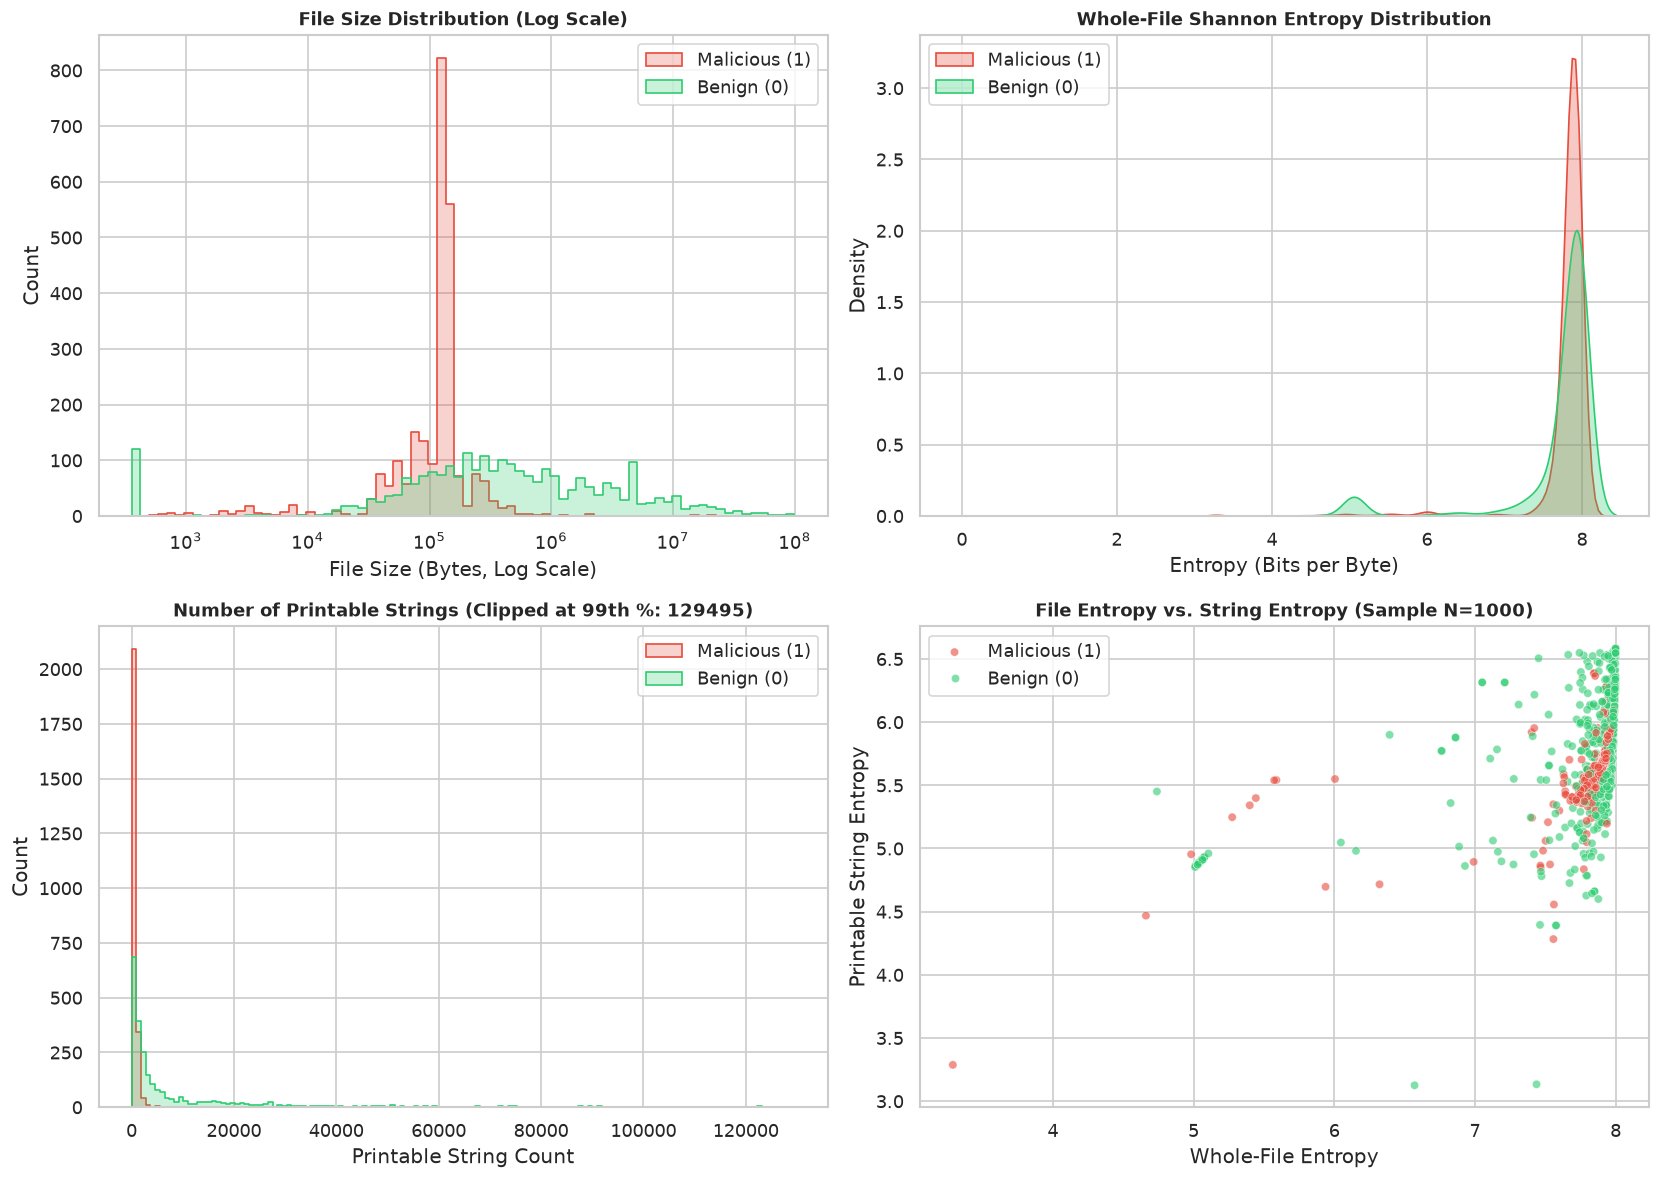

Saved figure to: <PROJECT_ROOT>\reports\figures\04_numeric_features_distribution.png


In [9]:
# Visualization: Distribution of Key Numeric Features across Benign vs Malicious
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Log File Size distribution
sns.histplot(data=df_sample_numeric, x='file_size', hue='label', log_scale=True,
             palette={0: '#2ecc71', 1: '#e74c3c'}, element='step', common_norm=False, ax=axes[0, 0])
axes[0, 0].set_title("File Size Distribution (Log Scale)", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("File Size (Bytes, Log Scale)")
axes[0, 0].legend(labels=['Malicious (1)', 'Benign (0)'])

# 2. Whole-File Entropy distribution
sns.kdeplot(data=df_sample_numeric, x='file_entropy', hue='label',
            palette={0: '#2ecc71', 1: '#e74c3c'}, common_norm=False, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Whole-File Shannon Entropy Distribution", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Entropy (Bits per Byte)")
axes[0, 1].legend(labels=['Malicious (1)', 'Benign (0)'])

# 3. Number of Strings distribution (clipped at 99th percentile for clarity)
p99 = df_sample_numeric['num_strings'].quantile(0.99)
sns.histplot(data=df_sample_numeric[df_sample_numeric['num_strings'] <= p99], x='num_strings', hue='label',
             palette={0: '#2ecc71', 1: '#e74c3c'}, element='step', common_norm=False, ax=axes[1, 0])
axes[1, 0].set_title(f"Number of Printable Strings (Clipped at 99th %: {p99:.0f})", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Printable String Count")
axes[1, 0].legend(labels=['Malicious (1)', 'Benign (0)'])

# 4. String Entropy vs File Entropy bivariate scatter/density
sns.scatterplot(data=df_sample_numeric.sample(1000, random_state=42), x='file_entropy', y='str_entropy', hue='label',
                palette={0: '#2ecc71', 1: '#e74c3c'}, alpha=0.6, s=25, ax=axes[1, 1])
axes[1, 1].set_title("File Entropy vs. String Entropy (Sample N=1000)", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Whole-File Entropy")
axes[1, 1].set_ylabel("Printable String Entropy")
axes[1, 1].legend(labels=['Malicious (1)', 'Benign (0)'])

plt.tight_layout()
fig_path = reports_dir / "04_numeric_features_distribution.png"
plt.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_path}")


---
## 7. Artifact Verification & Analytical Summary

### Verification of Saved Visualizations
All figures generated in this exploratory notebook have been stored in `reports/figures` in high-resolution format.


In [10]:
print("Exported Visualizations in reports/figures:")
saved_figures = sorted(glob.glob(str(reports_dir / "*.png")))
for fig_f in saved_figures:
    f_size_kb = Path(fig_f).stat().st_size / 1024
    print(f"  - {Path(fig_f).name} ({f_size_kb:.1f} KB)")
assert len(saved_figures) >= 4, f"Expected at least 4 saved figures, found {len(saved_figures)}"
print("\nAll exploratory figures successfully generated and verified!")


Exported Visualizations in reports/figures:
  - 01_label_distribution.png (118.9 KB)
  - 02_missing_values.png (78.0 KB)
  - 03_feature_families.png (118.7 KB)
  - 04_numeric_features_distribution.png (526.7 KB)
  - 05_class_balance_dedup.png (127.1 KB)
  - 06_file_size_distribution.png (170.3 KB)
  - 07_file_entropy_distribution.png (121.5 KB)
  - 08_string_stats_distribution.png (230.5 KB)
  - 09_mean_byte_histogram.png (560.7 KB)
  - 10_zero_inflation_histogram.png (98.1 KB)
  - 11_feature_skewness_distribution.png (77.4 KB)
  - 12_top25_effect_size_cohens_d.png (341.9 KB)
  - 13_top8_separating_violins.png (658.0 KB)
  - 14_string_indicators_heatmap.png (451.6 KB)
  - 15_non_histogram_correlation_heatmap.png (384.9 KB)
  - 16_pca_2d_projection.png (626.4 KB)
  - 17_train_test_distribution_shift.png (196.2 KB)
  - 18_scaling_before_after.png (617.8 KB)
  - 19_feature_reduction_waterfall.png (103.1 KB)

All exploratory figures successfully generated and verified!


### Executive Summary of Data Understanding Findings

| Dimension | Observation / Finding |
| :--- | :--- |
| **Dataset Shape** | **Train**: 104,000 rows across 52 weekly shards (2,000 rows/file).<br>**Test**: 24,000 rows across 12 weekly shards (2,000 rows/file).<br>**Total Rows**: 128,000 rows across 32 schema attributes. |
| **Class Balance** | **Perfect 50.0% / 50.0% balance** in both splits.<br>Train: 52,000 Benign (0) vs. 52,000 Malicious (1).<br>Test: 12,000 Benign (0) vs. 12,000 Malicious (1). No synthetic rebalancing is needed. |
| **Feature Families** | **4 Active PDF Families (696 total features)**:<br>1. *GeneralFileInfo* (7 features)<br>2. *ByteHistogram* (256 features)<br>3. *ByteEntropyHistogram* (256 features)<br>4. *StringExtractor* (177 features, including 76 regexes and PDF markers like `/URI`, `/FlateDecode`, `/EmbeddedFile`).<br>*Note*: 8 PE-specific structural families are present in the JSON schema but empty for PDFs. |
| **Data Leakage Check** | **Zero SHA256 overlap** between Train and Test ($N_{overlap} = 0$), verifying strict temporal isolation. |
| **Surprising Finding** | **Exact Row Duplication in Upstream Dataset**: Every weekly `.jsonl` file contains 2,000 records consisting of 1,000 unique samples repeated exactly twice (52,000 duplicate rows in train, 12,000 duplicate rows in test). This is an artifact of the raw EMBER2024 repository packaging. Deduplication will be an important consideration for model training pipelines. |
| **Missing Values** | Almost complete data completeness. The only null values reside in `family` and `family_confidence` (~75% missing in benign samples where malware families do not apply). All raw feature fields have 0 missing values. |
